# EASE trên dữ liệu thật — thứ tự nhân quả ở đuôi phân phối của 60 cổ phiếu HOSE

Notebook này áp dụng thuật toán **EASE** (*Extremal Ancestral SEarch*, Gnecco, Meinshausen, Peters & Engelke, 2021,
*Ann. Statist.* 49(3), `Paper/1. Causal discovery in heavy-tailed models.pdf`) cho lợi suất của 60 mã HOSE (10 ngành),
rồi so với các phương pháp đối chứng (baseline) mà bài báo dùng: **Pairwise LiNGAM**, **ICA-LiNGAM**, **Rank PC** và **thứ tự ngẫu nhiên**.
Kiểm chứng cài đặt và độ nhạy với biên độ ±7% nằm ở `01_ease_simulation.ipynb`; tổng hợp phát hiện ở `Processing_finding.ipynb`.

**Câu hỏi.** Khi một mã có cú sốc cực trị (tăng/giảm rất mạnh), cú sốc đó có "lan" sang mã khác không, và theo chiều nào?

**Ý tưởng của EASE.** Nếu $X_j$ gây ra $X_k$ (qua SCM tuyến tính, nhiễu đuôi dày cùng chỉ số $\alpha$) thì mọi giá trị
cực lớn của $X_j$ kéo theo giá trị cực lớn của $X_k$, còn chiều ngược lại thì không. Hệ số nhân quả đuôi đo điều đó:

$$\Gamma_{jk} = \lim_{u\to 1^-}\mathbb{E}\big[F_k(X_k)\,\big|\,F_j(X_j) > u\big],\qquad
\Psi_{jk} = \lim_{u\to 1^-}\mathbb{E}\big[\sigma(F_k(X_k))\,\big|\,\sigma(F_j(X_j)) > u\big],\ \ \sigma(v)=|2v-1|,$$

$F_j$: hàm phân phối của $X_j$. $\Gamma$ chỉ nhìn đuôi trên; $\Psi$ nhìn cả hai đuôi (và cả hệ số âm). Đọc kết quả theo Bảng 2 của bài báo:

| $\Psi_{12}$ | $\Psi_{21}$ | Kết luận |
|---|---|---|
| $=1$ | $\in(1/2,1)$ | $X_1$ gây ra $X_2$ |
| $\in(1/2,1)$ | $=1$ | $X_2$ gây ra $X_1$ |
| $\in(1/2,1)$ | $\in(1/2,1)$ | có nguyên nhân chung, không nhân quả trực tiếp |
| $=1/2$ | $=1/2$ | không liên hệ |

**Các bước:** (1) lọc GARCH; (2) kiểm tra giả định đuôi dày; (3) ước lượng $\hat\Psi$, chạy EASE; (4) bootstrap;
(5) độ nhạy theo số quan sát đuôi $k$; (6) các biến thể dữ liệu và đuôi; (7) baseline.

## 0. Thiết lập

Nạp module dùng chung: `eda_utils` (CSDL, style hình), `causal_tail` (hệ số đuôi, EASE, SID), `causal_baselines`
(LiNGAM, Rank PC), `tail_preprocessing` (GARCH, GPD, bootstrap). Lấy lợi suất log ngày $r_{i,t}$ trong khung phân tích
chung (từ 01/06/2018) và lợi suất tuần (tổng lợi suất log 5 phiên, chỉ giữ tuần cả 60 mã đều có phiên).

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as U
import causal_tail as CT
import causal_baselines as CB
import tail_preprocessing as TP

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.3f}".format)
SYMBOLS, COL, PAL = U.SYMBOLS, U.SYMBOL_COLORS, U.PALETTE
FOLDER = "processing"                      # hình png → report/figure/processing, pdf → report/pdf/processing, bảng → report/table/processing
METHOD_COLORS = {"EASE": PAL["blue_main"], "Pairwise LiNGAM": PAL["red_strong"], "ICA-LiNGAM": PAL["green_3"],
                 "Rank PC": PAL["violet"], "Ngẫu nhiên": PAL["neutral"]}

con = U.connect()
r = con.execute("SELECT * FROM v_returns_wide").df().set_index("time")[SYMBOLS].dropna()
r.index = pd.to_datetime(r.index)
weekly = r.resample("W-FRI").sum()[(r.resample("W-FRI").count() > 0).all(axis=1)]
print(f"Lợi suất ngày: T = {len(r)} phiên ({r.index[0]:%d/%m/%Y} → {r.index[-1]:%d/%m/%Y}); tuần: {len(weekly)} tuần")

Lợi suất ngày: T = 2103 phiên (05/06/2018 → 25/11/2026); tuần: 436 tuần


## 1. Lọc GARCH — đưa dữ liệu về gần độc lập cùng phân phối

**Tính gì:** với mỗi mã, khớp GARCH(1,1) với nhiễu Student-t rồi lấy phần dư chuẩn hoá $z_{i,t}$.

**Công thức.**
$$r_{i,t} = \mu_i + \sigma_{i,t}\,z_{i,t},\qquad \sigma_{i,t}^2 = \omega_i + a_i\,(r_{i,t-1}-\mu_i)^2 + b_i\,\sigma_{i,t-1}^2,\qquad z_{i,t}\sim t_{\nu_i}\ \text{(chuẩn hoá)}.$$
$a_i + b_i$: độ bền (persistence) của biến động; $\nu_i$: bậc tự do của nhiễu.

**Vì sao:** EDA (phát hiện 5) cho thấy hiệu ứng ARCH mạnh — các phiên cực trị đi theo cụm. Định lý 2 của bài báo cần các
quan sát độc lập; nếu không lọc, $k$ phiên cực trị lớn nhất có thể chỉ đến từ 1–2 đợt khủng hoảng. Lọc GARCH cũng có lợi phụ:
mức trần/sàn ±7% trở thành $\pm 7\%/\sigma_{i,t}$ — thay đổi theo ngày, nên các quan sát **không còn dồn đúng một giá trị**.

**Các bước:** (1) khớp mô hình (`arch`); (2) kiểm định Ljung–Box ($m=10$) cho $r_t^2$ và $z_t^2$; (3) lưu $z$ vào
`data/processed/garch_std_resid.parquet`.

In [2]:
from statsmodels.stats.diagnostic import acorr_ljungbox

z, garch_params = TP.garch_standardize(r)
z = z.dropna()
lb = pd.DataFrame({s: {"LB(10) p của r²": acorr_ljungbox(r[s] ** 2, lags=[10])["lb_pvalue"].iloc[0],
                       "LB(10) p của z²": acorr_ljungbox(z[s] ** 2, lags=[10])["lb_pvalue"].iloc[0],
                       "LB(10) p của z": acorr_ljungbox(z[s], lags=[10])["lb_pvalue"].iloc[0]} for s in SYMBOLS}).T
garch_params["omega (×1e-4)"] = garch_params["omega"].astype(float) * 1e4      # phương sai, đơn vị lợi suất gốc
garch_tab = pd.concat([garch_params[["omega (×1e-4)", "alpha[1]", "beta[1]", "persistence", "nu", "converged"]], lb], axis=1)
U.save_table(garch_tab, "02_garch_params", FOLDER)
z.to_parquet(ROOT / "data" / "processed" / "garch_std_resid.parquet")

n_cap = {s: (r[s].abs() >= 0.065).sum() for s in SYMBOLS}
print(f"Số phiên |r| ≥ 6,5% (gần trần/sàn) so với 2k = {2 * CT.default_k(len(r))} phiên cực trị EASE dùng:", n_cap)
garch_tab

Số phiên |r| ≥ 6,5% (gần trần/sàn) so với 2k = 42 phiên cực trị EASE dùng: {'VCB': np.int64(17), 'BID': np.int64(50), 'CTG': np.int64(45), 'TCB': np.int64(48), 'MBB': np.int64(35), 'STB': np.int64(79), 'VPB': np.int64(58), 'HDB': np.int64(36), 'EIB': np.int64(73), 'TPB': np.int64(42), 'VIC': np.int64(77), 'VHM': np.int64(74), 'NVL': np.int64(94), 'KDH': np.int64(39), 'CII': np.int64(143), 'VRE': np.int64(78), 'DXG': np.int64(157), 'PDR': np.int64(91), 'DIG': np.int64(207), 'KBC': np.int64(105), 'TCH': np.int64(145), 'NLG': np.int64(76), 'HDG': np.int64(98), 'HDC': np.int64(151), 'VNM': np.int64(17), 'MSN': np.int64(42), 'SAB': np.int64(23), 'MWG': np.int64(55), 'FRT': np.int64(138), 'DGW': np.int64(159), 'PNJ': np.int64(69), 'VHC': np.int64(83), 'TCM': np.int64(80), 'ANV': np.int64(163), 'GAS': np.int64(60), 'PLX': np.int64(52), 'GEX': np.int64(138), 'POW': np.int64(65), 'PVD': np.int64(134), 'PVT': np.int64(92), 'PC1': np.int64(109), 'REE': np.int64(36), 'HPG': np.int64(39), 'NKG': np

,omega (×1e-4),alpha[1],beta[1],persistence,nu,converged,LB(10) p của r²,LB(10) p của z²,LB(10) p của z
VCB,0.259,0.233,0.724,0.957,3.619,True,0.000,0.761,0.826
BID,0.107,0.111,0.877,0.988,4.163,True,0.000,0.968,0.593
CTG,0.109,0.117,0.875,0.992,3.830,True,0.000,0.844,0.397
TCB,0.195,0.108,0.861,0.969,3.710,True,0.000,0.434,0.080
MBB,0.141,0.127,0.853,0.980,3.673,True,0.000,0.680,0.803
STB,0.130,0.114,0.876,0.990,4.337,True,0.000,0.869,0.884
VPB,0.077,0.088,0.905,0.993,4.149,True,0.000,0.498,0.022
HDB,0.142,0.122,0.875,0.998,3.214,True,0.000,0.448,0.339
EIB,0.156,0.191,0.809,1.000,3.540,True,0.000,0.273,0.840
TPB,0.108,0.131,0.869,1.000,3.289,True,0.000,0.116,0.686


### Phân tích

- Biến động **rất bền**: $a_i + b_i$ = 0,90 (VNM) đến 1,00 (23/60 mã sát IGARCH, gồm VIC, VHM, NVL, KDH, GAS, EIB, TPB); bậc tự do nhiễu $\nu$ = 3,0–8,1: phần dư vẫn đuôi dày. Mọi khớp hội tụ.
- Lọc có hiệu quả: Ljung–Box của $r^2$ có p ≈ 0 ở cả 60 mã, của $z^2$ chỉ còn ý nghĩa ở 3 mã (DXG, TCM, NKG) — **gần hết hiệu ứng ARCH**. 28/60 mã còn tự tương quan bậc thấp nhẹ ở mức trung bình
  ($z$ có p < 0,05), chủ yếu là mã vừa và nhỏ — ít ảnh hưởng tới phân tích đuôi.
- Số phiên $|r| \ge 6{,}5\%$ từ 17 (VCB, VNM) đến 207 (DIG); ở phần lớn mã con số này **vượt** $2k = 42$ — trên $r$ thô, tập cực trị chủ yếu là phiên trần/sàn.
  Trên $z$, ngưỡng ±7%/σₜ thay đổi theo ngày nên cực trị được xếp theo mức bất thường so với biến động lúc đó.

## 2. Kiểm tra giả định: nhiễu đuôi dày với chỉ số đuôi chung

**Tính gì:** tham số hình dạng $\xi$ của phân phối Pareto tổng quát (GPD) cho phần vượt ngưỡng phân vị 95%, đuôi trên và đuôi dưới,
trên ba biến thể dữ liệu: lợi suất ngày $r$, phần dư GARCH $z$, lợi suất tuần — như mục 5.2 của bài báo.

**Công thức.** Với ngưỡng $u$ và $Y = X - u \mid X > u$:
$$P(Y \le y) = 1 - \Big(1 + \xi\,\frac{y}{\beta}\Big)^{-1/\xi},\qquad \widehat{\mathrm{SE}}(\hat\xi)\approx\frac{1+\hat\xi}{\sqrt{n_u}}\ \text{(Coles, 2001)},$$
$n_u$: số quan sát vượt ngưỡng. $\xi>0$ ⇔ đuôi dày dạng Pareto với chỉ số đuôi $\alpha = 1/\xi$; $\xi = 0$: đuôi mũ (như chuẩn);
$\xi<0$: đuôi **bị chặn** (có cận trên hữu hạn).

**Đọc kết quả:** EASE cần $\xi>0$ (đuôi dày) và các mã có $\xi$ **gần nhau** (khoảng $\hat\xi\pm2\,\mathrm{SE}$ chồng lên nhau).
Đường đứt nét đánh dấu $\xi=0$.

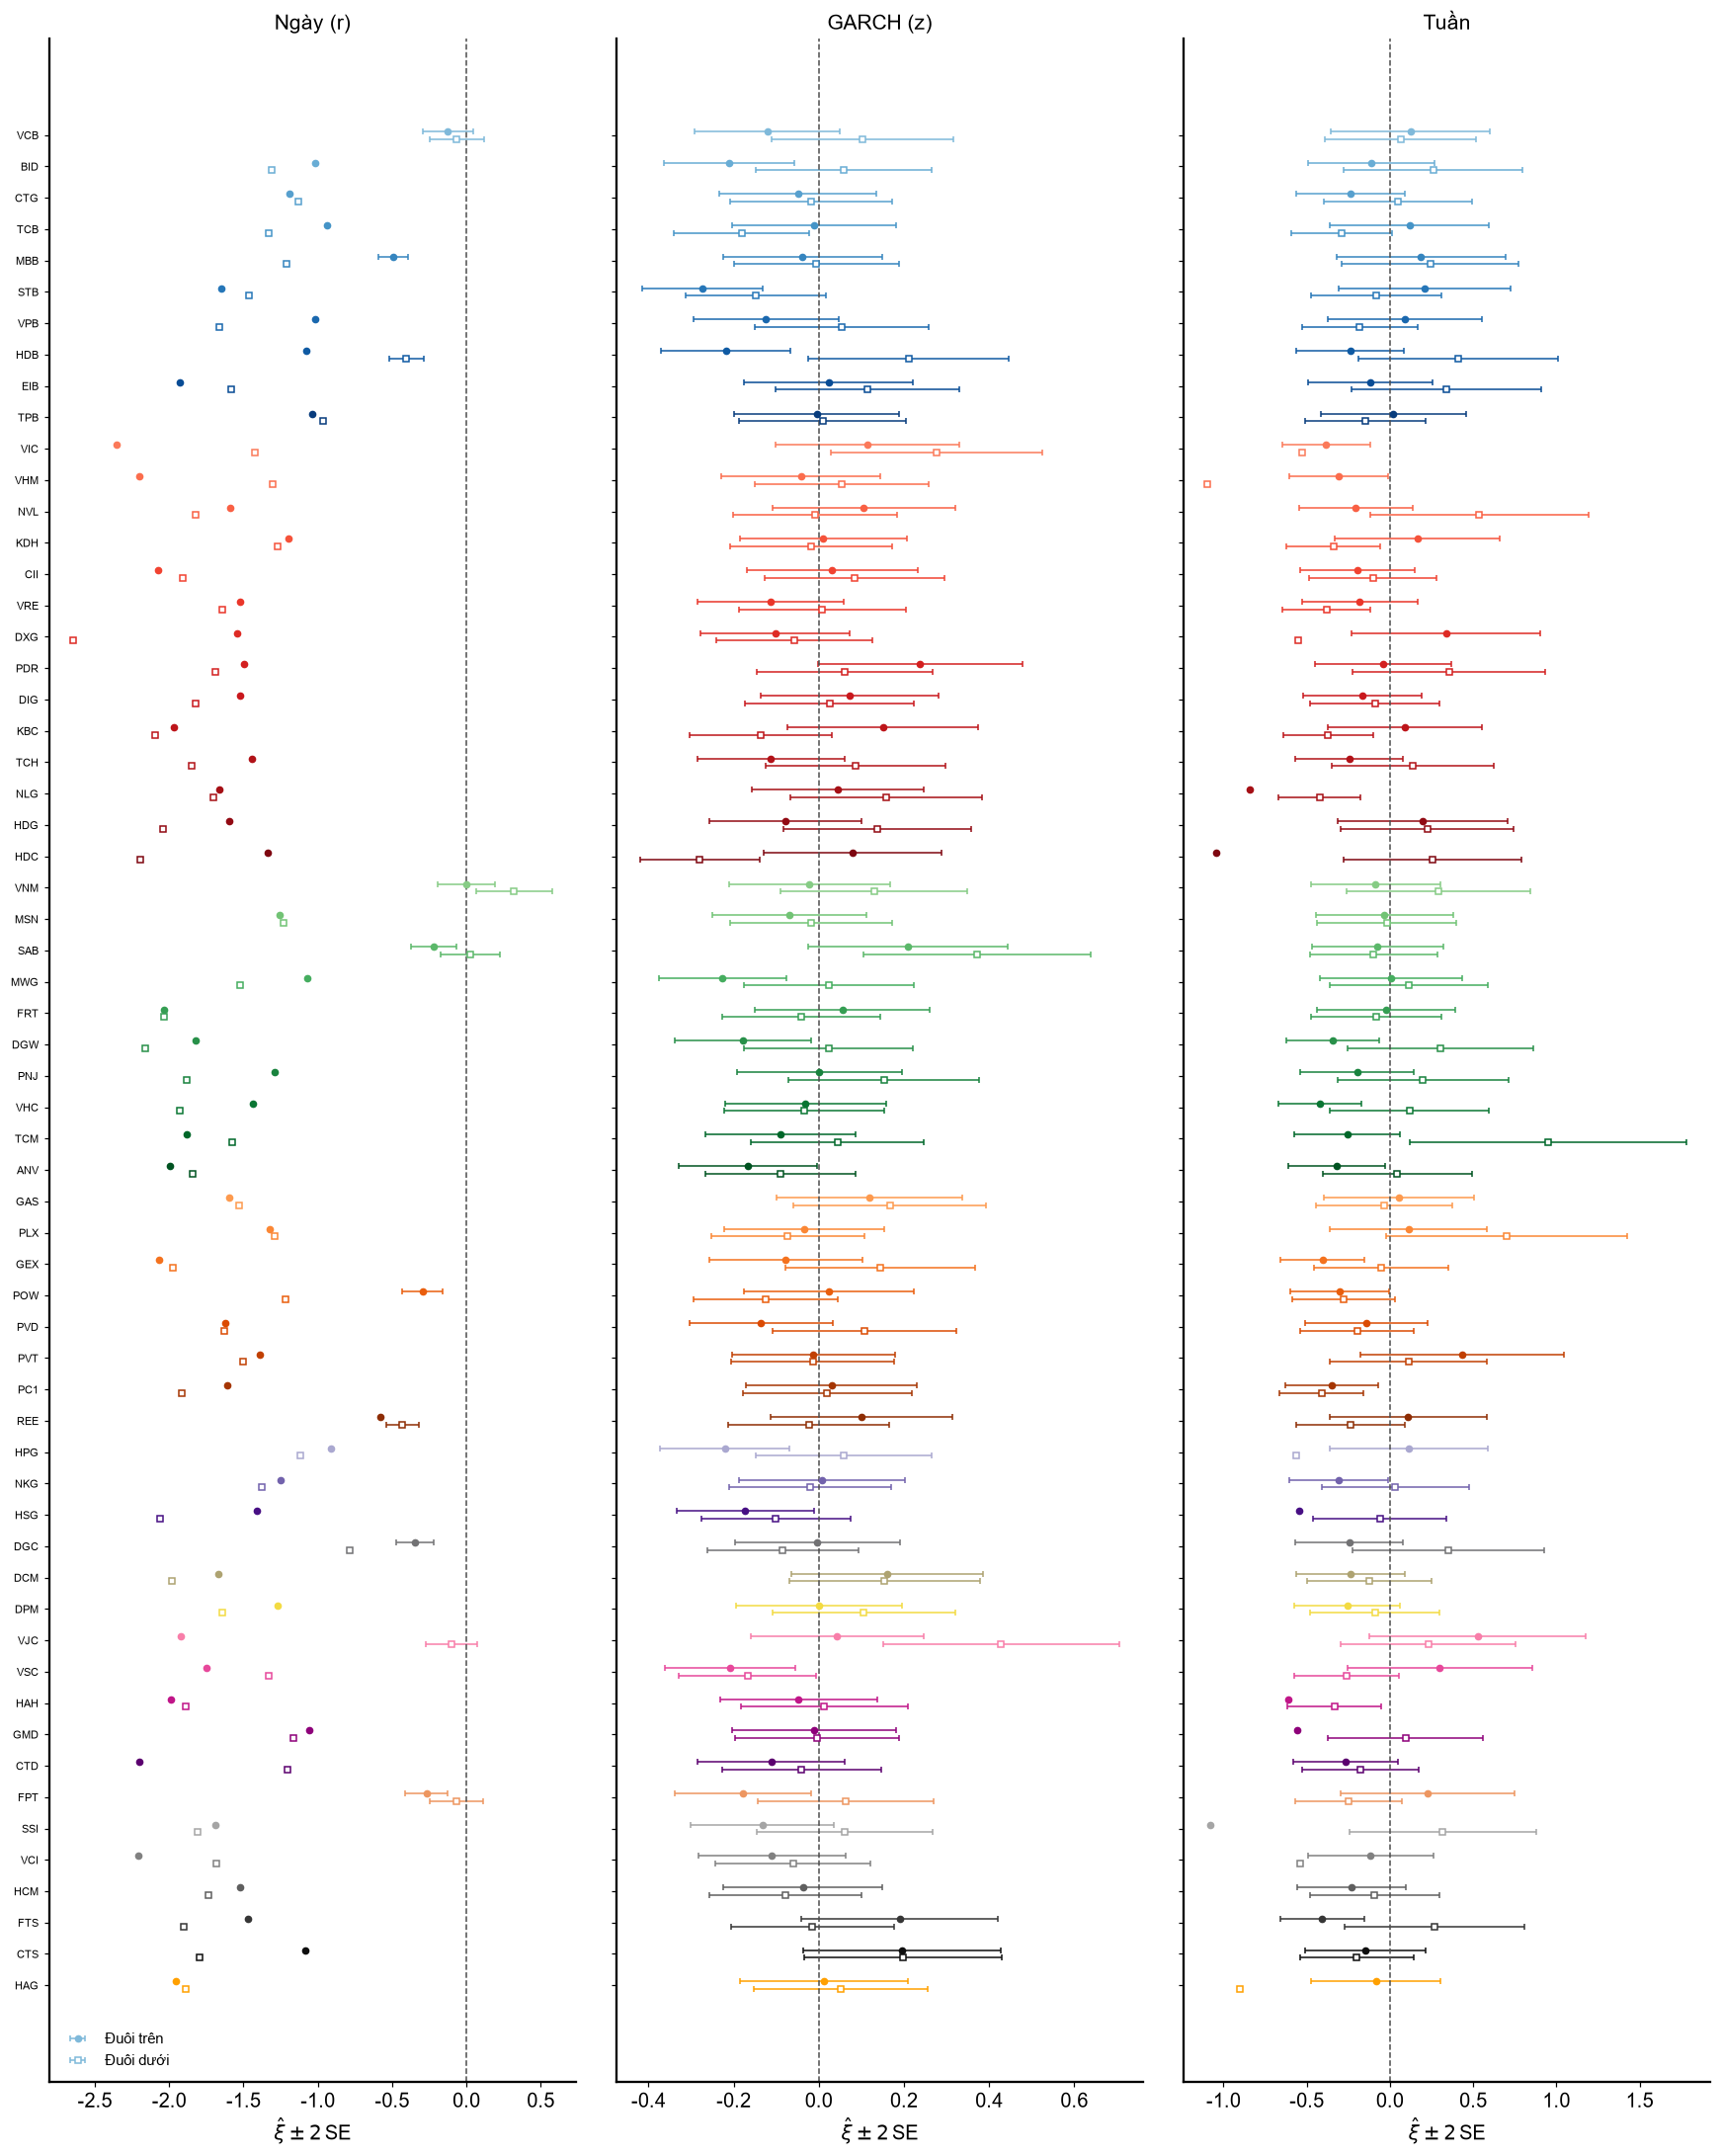

bien_the GARCH (z)        Ngày (r)          Tuần       
duoi          dưới   trên     dưới   trên   dưới   trên
ma                                                     
VCB          0.103 -0.121   -0.064 -0.125  0.063  0.123
BID          0.059 -0.212   -1.313 -1.020  0.261 -0.113
CTG         -0.018 -0.049   -1.129 -1.189  0.048 -0.237
TCB         -0.181 -0.011   -1.331 -0.936 -0.288  0.118
MBB         -0.006 -0.038   -1.211 -0.490  0.242  0.187
STB         -0.148 -0.274   -1.463 -1.647 -0.081  0.208
VPB          0.054 -0.124   -1.666 -1.018 -0.181  0.087
HDB          0.211 -0.218   -0.404 -1.077  0.411 -0.239
EIB          0.115  0.023   -1.583 -1.928  0.338 -0.118
TPB          0.009 -0.005   -0.961 -1.035 -0.148  0.020
VIC          0.276  0.114   -1.422 -2.353 -0.527 -0.383
VHM          0.053 -0.042   -1.302 -2.203 -1.096 -0.307
NVL         -0.009  0.106   -1.821 -1.592  0.537 -0.205
KDH         -0.019  0.011   -1.271 -1.194 -0.340  0.164
CII          0.084  0.031   -1.906 -2.076 -0.101 -0.194
VRE          0.008 -0.113   -1.645 -1.522 -0.380 -0.181
DXG         -0.058 -0.103   -2.647 -1.541 -0.550  0.336
PDR          0.061  0.238   -1.688 -1.493  0.356 -0.042
DIG          0.025  0.073   -1.821 -1.521 -0.091 -0.165
KBC         -0.136  0.151   -2.096 -1.968 -0.371  0.088
TCH          0.087 -0.113   -1.847 -1.443  0.137 -0.244
NLG          0.158  0.045   -1.701 -1.661 -0.422 -0.841
HDG          0.137 -0.079   -2.038 -1.594  0.223  0.199
HDC         -0.279  0.079   -2.193 -1.336  0.255 -1.043
VNM          0.129 -0.022    0.319 -0.002  0.292 -0.088
MSN         -0.018 -0.069   -1.231 -1.260 -0.019 -0.033
SAB          0.372  0.209    0.028 -0.221 -0.098 -0.075
MWG          0.024 -0.226   -1.525 -1.070  0.113  0.005
FRT         -0.041  0.055   -2.031 -2.035 -0.084 -0.024
DGW          0.023 -0.178   -2.161 -1.821  0.303 -0.342
PNJ          0.153  0.002   -1.884 -1.290  0.199 -0.198
VHC         -0.035 -0.031   -1.931 -1.434  0.116 -0.420
TCM          0.044 -0.090   -1.579 -1.881  0.950 -0.255
ANV         -0.090 -0.166   -1.843 -1.992  0.045 -0.317
GAS          0.167  0.119   -1.530 -1.593 -0.036  0.053
PLX         -0.073 -0.034   -1.292 -1.326  0.702  0.110
GEX          0.145 -0.077   -1.977 -2.070 -0.051 -0.405
POW         -0.125  0.024   -1.214 -0.296 -0.279 -0.305
PVD          0.108 -0.136   -1.633 -1.624 -0.197 -0.142
PVT         -0.014 -0.012   -1.506 -1.389  0.111  0.435
PC1          0.020  0.030   -1.914 -1.609 -0.410 -0.350
REE         -0.023  0.100   -0.431 -0.582 -0.235  0.110
HPG          0.058 -0.221   -1.116 -0.910 -0.564  0.111
NKG         -0.021  0.007   -1.376 -1.248  0.033 -0.308
HSG         -0.101 -0.173   -2.062 -1.408 -0.060 -0.544
DGC         -0.085 -0.003   -0.782 -0.349  0.351 -0.245
DCM          0.154  0.160   -1.980 -1.666 -0.125 -0.237
DPM          0.105  0.000   -1.641 -1.269 -0.091 -0.256
VJC          0.428  0.043   -0.100 -1.919  0.232  0.526
VSC         -0.167 -0.209   -1.327 -1.747 -0.261  0.300
HAH          0.013 -0.047   -1.885 -1.989 -0.335 -0.614
GMD         -0.004 -0.012   -1.162 -1.058  0.093 -0.558
CTD         -0.040 -0.111   -1.202 -2.199 -0.178 -0.266
FPT          0.062 -0.178   -0.067 -0.270 -0.248  0.224
SSI          0.061 -0.133   -1.806 -1.688  0.318 -1.079
VCI         -0.061 -0.110   -1.680 -2.207 -0.539 -0.116
HCM         -0.078 -0.038   -1.735 -1.524 -0.092 -0.232
FTS         -0.016  0.190   -1.902 -1.471  0.268 -0.409
CTS          0.198  0.196   -1.795 -1.085 -0.201 -0.150
HAG          0.051  0.012   -1.891 -1.956 -0.899 -0.085

In [3]:
variants = {"Ngày (r)": r, "GARCH (z)": z, "Tuần": weekly}
rows = []
for vname, X in variants.items():
    for s in SYMBOLS:
        for tail, up in (("trên", True), ("dưới", False)):
            g = TP.gpd_tail_shape(X[s].values, q=0.95, upper=up)
            rows.append({"bien_the": vname, "ma": s, "duoi": tail, "xi": g["xi"], "se": g["se"], "n_vuot": g["n_exc"]})
gpd = pd.DataFrame(rows)
U.save_table(gpd.set_index(["bien_the", "ma", "duoi"]), "02_gpd_shape", FOLDER)

fig, axes = plt.subplots(1, 3, figsize=(16, 0.3 * len(SYMBOLS) + 2), sharey=True)
for ax, vname in zip(axes, variants):
    d = gpd[gpd.bien_the == vname]
    for t, (tail, mk, dx) in enumerate((("trên", "o", -0.12), ("dưới", "s", 0.12))):
        dd = d[d.duoi == tail]
        for i, s in enumerate(SYMBOLS):
            row = dd[dd.ma == s].iloc[0]
            ax.errorbar(row.xi, i + dx, xerr=0 if np.isnan(row.se) else 2 * row.se, fmt=mk, color=COL[s], ms=4, capsize=2, lw=1.0,
                        mfc=COL[s] if tail == "trên" else "white", label=f"Đuôi {tail}" if i == 0 else None)
    ax.axvline(0, color=PAL["gray_dark"], ls="--", lw=1)
    ax.set_yticks(range(len(SYMBOLS)), SYMBOLS, fontsize=7.5); ax.invert_yaxis()
    ax.set_xlabel(r"$\hat\xi \pm 2\,$SE"); ax.set_title(vname)
axes[0].legend(loc="lower left", fontsize=10)
U.finalize_figure(fig, "02_gpd_shape", folder=FOLDER); plt.show()
gpd.pivot_table(index="ma", columns=["bien_the", "duoi"], values="xi").loc[SYMBOLS]

### Phân tích

- **Lợi suất ngày thô:** $\hat\xi$ từ −2,65 đến +0,32; 92% (đuôi × mã) có $\hat\xi < -0{,}3$ — đuôi **bị chặn** bởi biên độ ±7%.
- **Phần dư GARCH $z$:** $\hat\xi$ từ −0,28 đến +0,43, không giá trị nào dưới −0,3; chỉ 3/120 đuôi có $\hat\xi$ dương có ý nghĩa ($\hat\xi - 2\mathrm{SE} > 0$). Giả định **chỉ số đuôi chung**
  chấp nhận được ở mức thô, giả định **đuôi Pareto** ($\xi > 0$) chỉ thoả ở một phần các mã.
- **Lợi suất tuần:** −1,1 đến +0,95, ít bị chặn hơn ngày nhưng $n$ chỉ còn 436 tuần nên ước lượng dao động mạnh.
- Hệ quả: kết luận EASE trên dữ liệu thật mang tính gợi ý; mô phỏng (notebook 01) cho biết sai số kỳ vọng khi $\alpha \approx 3$.

## 3. Ma trận $\hat\Psi$ và thứ tự nhân quả EASE

**Tính gì:** ước lượng $\hat\Psi_{jk}$ cho 3.540 cặp có thứ tự trên phần dư GARCH $z$, với $k = \lfloor n^{0,4}\rfloor$ như bài báo.

**Công thức** (ước lượng thực nghiệm, công thức (8) và mục 4.1 của bài báo):
$$\hat F_k(x) = \frac1n\sum_{i=1}^n \mathbb 1\{X_{ik}\le x\},\qquad
\hat\Psi_{jk} = \frac{1}{2k}\Big[\sum_{i\in\mathcal U_j}\sigma\big(\hat F_k(X_{ik})\big) + \sum_{i\in\mathcal L_j}\sigma\big(\hat F_k(X_{ik})\big)\Big],$$
$\mathcal U_j$ ($\mathcal L_j$): chỉ số của $k$ phiên có $X_j$ lớn nhất (nhỏ nhất). Phiên trùng giá trị tại ngưỡng được chọn ngẫu nhiên (seed cố định).

**EASE** (mục 3.1): ở bước $s$, với mỗi nút $i$ còn lại tính $M_i = \max_{j\neq i}\hat\Psi_{ji}$ — mức độ $i$ "bị" một nút khác
kéo theo ở đuôi; chọn nút có $M_i$ **nhỏ nhất** làm gốc, bỏ nó ra, lặp lại. Kết quả là một **thứ tự nhân quả** (gốc trước):
nó nói "mã đứng sau không gây ra mã đứng trước", **không** khẳng định mã trước gây ra mã sau.

**Ma trận bất đối xứng** $D_{jk} = \hat\Psi_{jk} - \hat\Psi_{kj}$: $D_{jk} > 0$ là dấu hiệu (yếu) cho chiều $j \to k$.

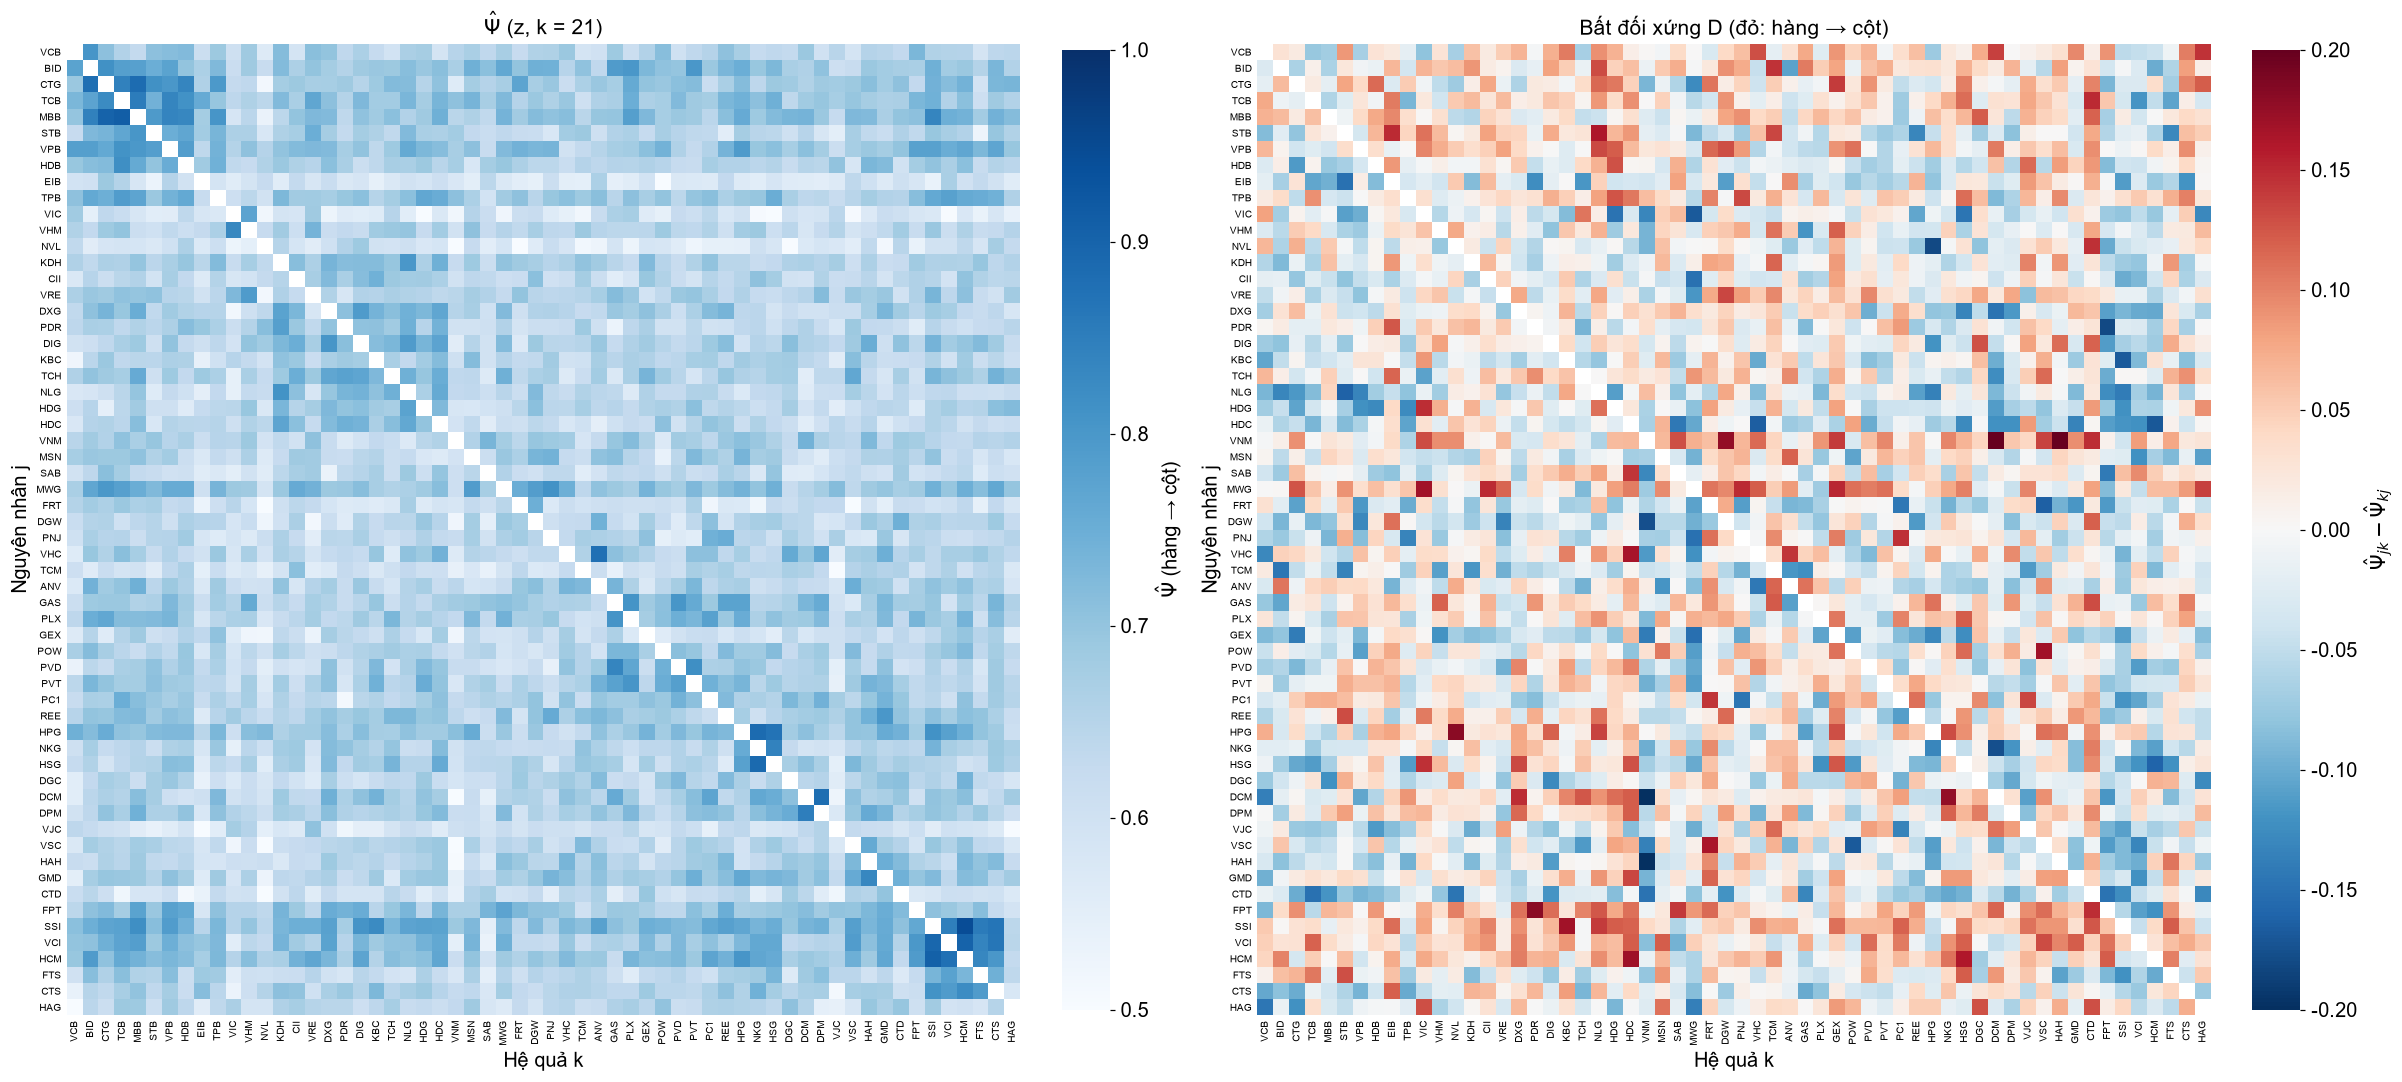

Thứ tự nhân quả EASE (gốc → lá): VNM → VJC → NVL → TCM → HAG → SAB → TCH → PDR → CTD → VHC → GEX → POW → DGC → CII → EIB → VRE → FRT → MWG → DGW → MSN → PNJ → VHM → VIC → HDC → ANV → PC1 → HDG → REE → GMD → HAH → VCB → VSC → FPT → NLG → KDH → PVD → PVT → DXG → HPG → TPB → DIG → GAS → PLX → STB → KBC → HDB → VPB → HSG → NKG → DCM → DPM → FTS → CTS → VCI → BID → MBB → CTG → TCB → SSI → HCM


,chon,VCB,BID,CTG,TCB,MBB,STB,VPB,HDB,EIB,...,HAH,GMD,CTD,FPT,SSI,VCI,HCM,FTS,CTS,HAG
buoc,,,,,,,,,,,,,,,,,,,,,
1,VNM,0.782,0.877,0.902,0.911,0.884,0.814,0.836,0.834,0.757,...,0.833,0.799,0.745,0.798,0.905,0.875,0.944,0.854,0.867,0.734
2,VJC,0.782,0.877,0.902,0.911,0.884,0.814,0.836,0.834,0.757,...,0.833,0.799,0.745,0.798,0.905,0.875,0.944,0.854,0.867,0.734
3,NVL,0.782,0.877,0.902,0.911,0.884,0.814,0.836,0.834,0.757,...,0.833,0.799,0.745,0.798,0.905,0.875,0.944,0.854,0.867,0.734
4,TCM,0.782,0.877,0.902,0.911,0.884,0.814,0.836,0.834,0.757,...,0.833,0.799,0.745,0.798,0.905,0.875,0.944,0.854,0.867,0.734
5,HAG,0.782,0.877,0.902,0.911,0.884,0.814,0.836,0.834,0.757,...,0.833,0.799,0.745,0.798,0.905,0.875,0.944,0.854,0.867,0.734
6,SAB,0.782,0.877,0.902,0.911,0.884,0.814,0.836,0.834,0.757,...,0.833,0.799,0.745,0.798,0.905,0.875,0.944,0.854,0.867,NaN
7,TCH,0.782,0.877,0.902,0.911,0.884,0.814,0.836,0.834,0.757,...,0.833,0.799,0.745,0.798,0.905,0.875,0.944,0.854,0.867,NaN
8,PDR,0.782,0.877,0.902,0.911,0.884,0.814,0.836,0.834,0.757,...,0.833,0.799,0.745,0.798,0.905,0.875,0.944,0.854,0.867,NaN
9,CTD,0.782,0.877,0.902,0.911,0.884,0.814,0.836,0.834,0.757,...,0.833,0.799,0.745,0.798,0.905,0.875,0.944,0.854,0.867,NaN


In [4]:
n = len(z); K = CT.default_k(n)
Psi = CT.tail_coef_matrix(z, k=K, kind="psi")
D = Psi - Psi.T
order_main = CT.ease(Psi)
path = CT.ease_scores_path(Psi)
U.save_table(Psi, "02_psi_matrix", FOLDER); U.save_table(path, "02_ease_path", FOLDER)

fig, axes = plt.subplots(1, 2, figsize=(22, 10))
U.make_heatmap(axes[0], Psi, cmap="Blues", vmin=0.5, vmax=1, fmt=None, tick_fontsize=6.5, cbar_label=r"$\hat\Psi$ (hàng → cột)",
               title=rf"$\hat\Psi$ (z, k = {K})")
U.make_heatmap(axes[1], D, cmap="RdBu_r", vmin=-0.2, vmax=0.2, fmt=None, tick_fontsize=6.5, cbar_label=r"$\hat\Psi_{jk}-\hat\Psi_{kj}$",
               title="Bất đối xứng D (đỏ: hàng → cột)")
for ax in axes:
    ax.set_xlabel("Hệ quả k"); ax.set_ylabel("Nguyên nhân j")
U.finalize_figure(fig, "02_psi_matrix", folder=FOLDER); plt.show()
print("Thứ tự nhân quả EASE (gốc → lá):", " → ".join(order_main))
path

### Phân tích

- $\overline{\hat\Psi}$ = 0,656 trên 3.540 cặp (0,47–0,94); **cùng ngành 0,694 > khác ngành 0,651**. Lớn nhất là các ngành hẹp: SSI→HCM 0,94, HCM→SSI 0,91, VCI→HCM 0,90 (chứng khoán),
  MBB→TCB 0,91, MBB→CTG 0,90 (ngân hàng), HSG→NKG 0,89, HPG→NKG 0,89 (thép).
- Không cặp nào đạt 1 ở một chiều và < 1 ở chiều kia theo cách Bảng 2 đòi hỏi; đa số cặp có cả hai hệ số trong (1/2, 1) — mẫu hình **nguyên nhân chung**.
- **Thứ tự EASE** (gốc → lá): VNM → VJC → NVL → TCM → HAG → SAB → TCH → PDR → … → STB → KBC → HDB → VPB → HSG → NKG → DCM → DPM → FTS → CTS → VCI → BID → MBB → CTG → TCB → SSI → HCM.
  Đầu danh sách là các mã **ít gắn với thị trường** (VNM, VJC, SAB, NVL, HAG); **cuối danh sách là chứng khoán, ngân hàng lớn, thép và phân bón** — đúng các ngành hẹp có phụ thuộc
  trong ngành mạnh nhất (EDA). "Gốc" nghĩa là *ít bị mã khác kéo theo*, không phải *gây ra mã khác*.

## 4. Bootstrap: thứ tự EASE ổn định đến đâu?

**Tính gì:** lấy mẫu lại có hoàn lại $B = 500$ lần **theo dòng** (giữ nguyên quan hệ đồng thời giữa 60 mã trong cùng phiên — hợp lệ
vì $z$ gần độc lập theo thời gian sau khi lọc GARCH), mỗi lần tính lại $\hat\Psi^{(b)}$ và thứ tự EASE $\hat\pi^{(b)}$.

**Đầu ra:** (a) tần suất mỗi mã đứng ở vị trí 1…5; (b) khoảng tin cậy bootstrap 90% (phân vị 5%–95%) của $D_{jk}$ —
cặp nào có khoảng không chứa 0 thì chiều bất đối xứng là đáng tin ở mức 10%.

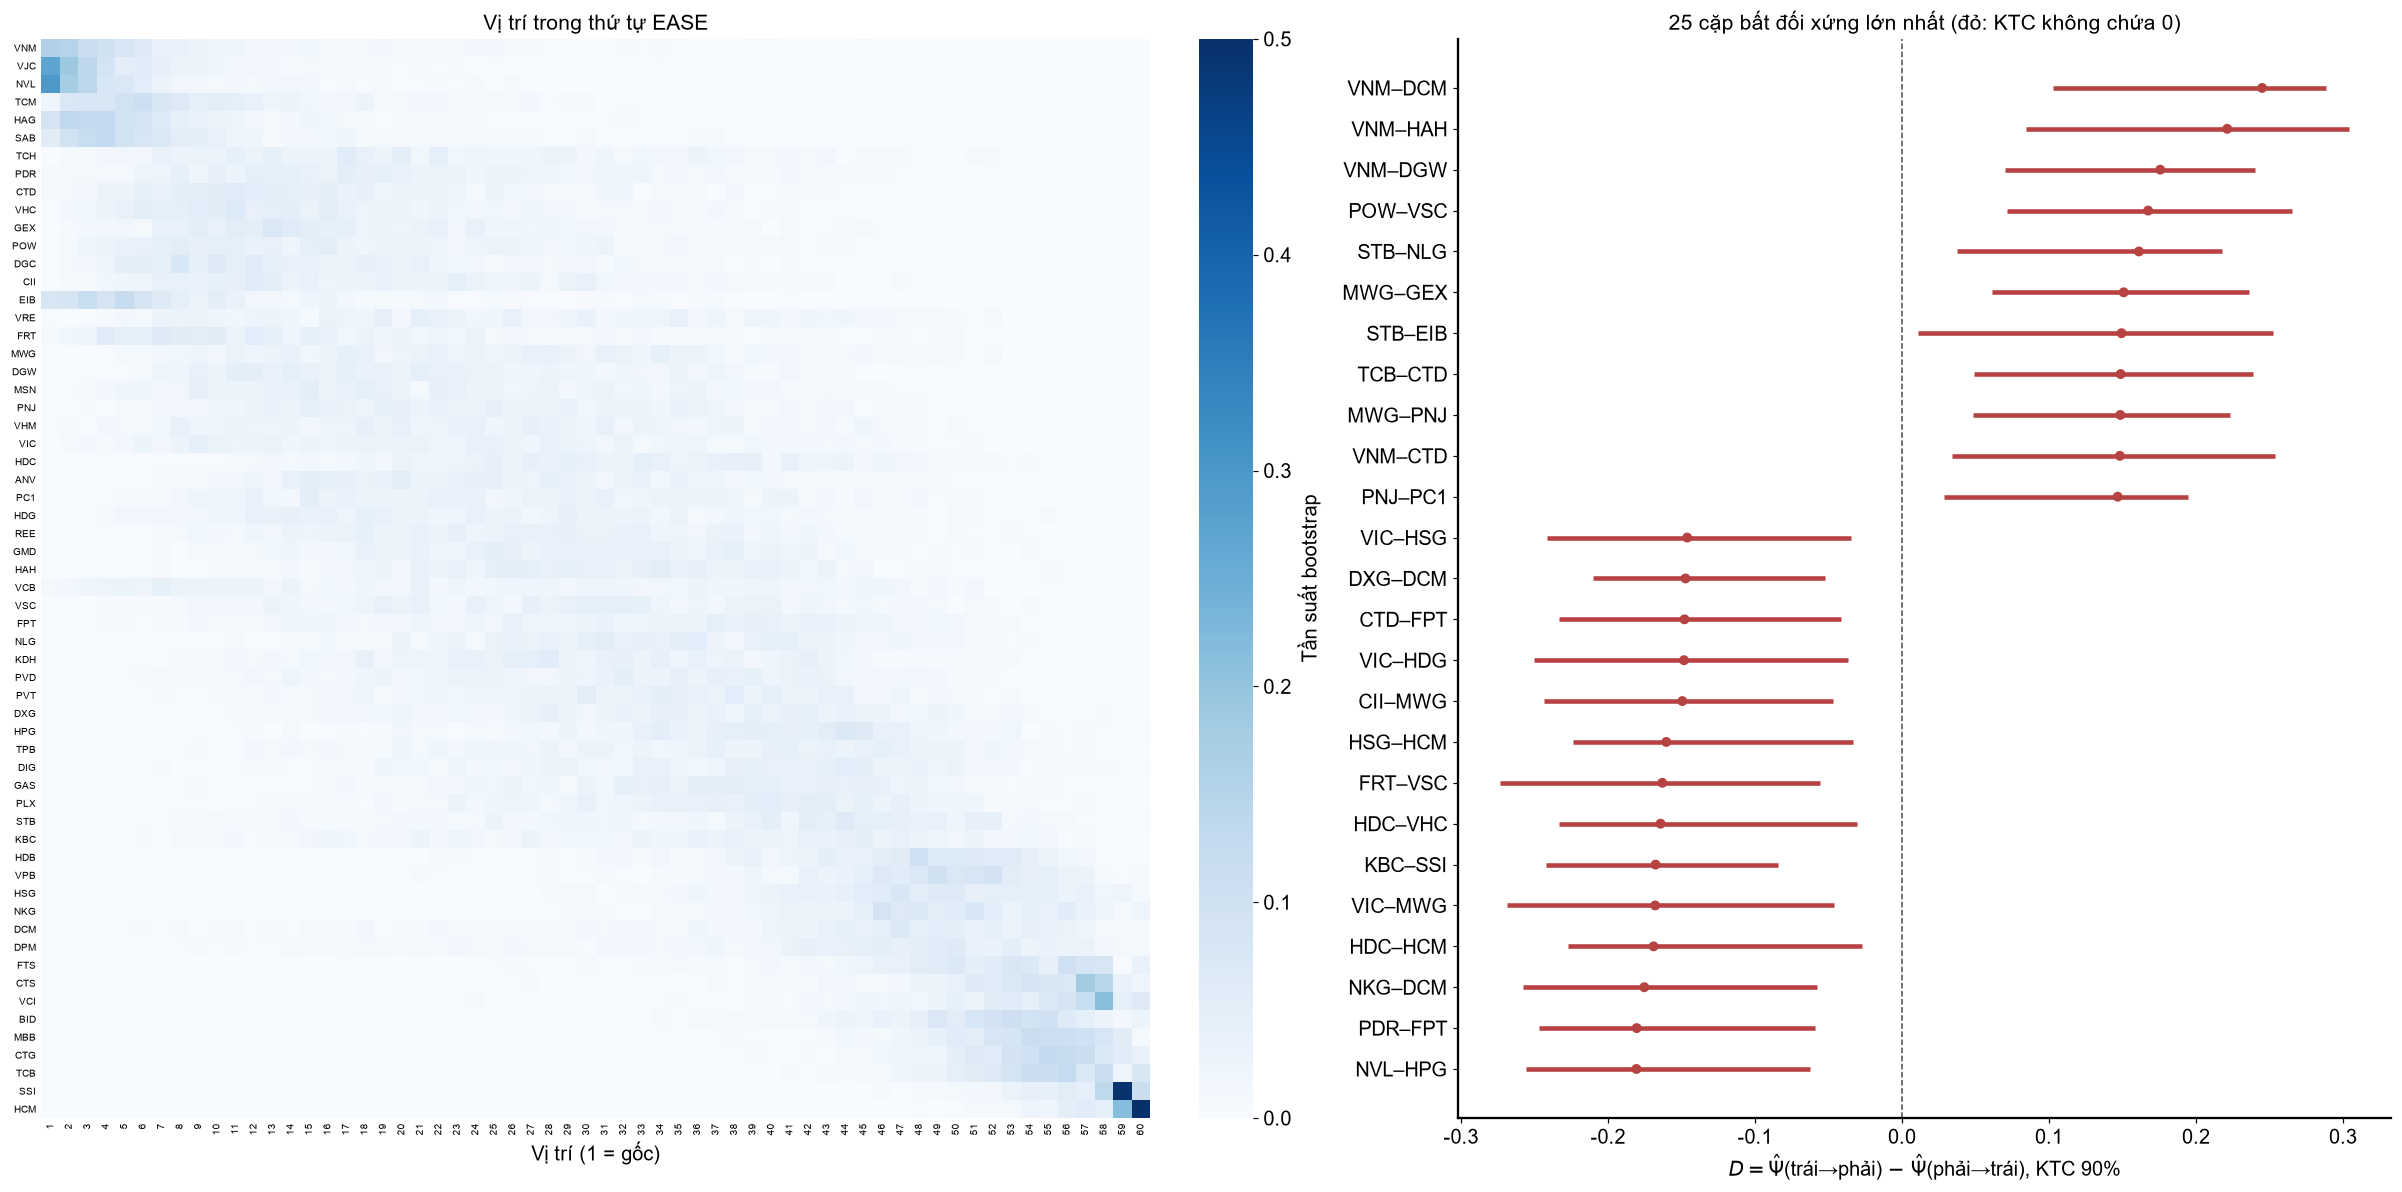

Tỷ lệ bootstrap cho đúng thứ tự ['VNM', 'VJC', 'NVL', 'TCM', 'HAG', 'SAB', 'TCH', 'PDR', 'CTD', 'VHC', 'GEX', 'POW', 'DGC', 'CII', 'EIB', 'VRE', 'FRT', 'MWG', 'DGW', 'MSN', 'PNJ', 'VHM', 'VIC', 'HDC', 'ANV', 'PC1', 'HDG', 'REE', 'GMD', 'HAH', 'VCB', 'VSC', 'FPT', 'NLG', 'KDH', 'PVD', 'PVT', 'DXG', 'HPG', 'TPB', 'DIG', 'GAS', 'PLX', 'STB', 'KBC', 'HDB', 'VPB', 'HSG', 'NKG', 'DCM', 'DPM', 'FTS', 'CTS', 'VCI', 'BID', 'MBB', 'CTG', 'TCB', 'SSI', 'HCM']: 0.0%


,cap,D,q05,q95,co_y_nghia_10pct
0,VCB–BID,0.029,-0.056,0.128,False
1,VCB–CTG,0.018,-0.071,0.149,False
2,VCB–TCB,-0.076,-0.161,0.034,False
3,VCB–MBB,-0.069,-0.129,0.072,False
4,VCB–STB,0.087,0.012,0.208,True
...,...,...,...,...,...
1765,HCM–CTS,-0.023,-0.094,0.066,False
1766,HCM–HAG,0.029,-0.084,0.111,False
1767,FTS–CTS,-0.044,-0.117,0.078,False
1768,FTS–HAG,0.052,-0.075,0.131,False


In [5]:
B = 500
boot = TP.bootstrap_coef(z, k=K, kind="psi", B=B, seed=2026)
orders = [CT.ease(pd.DataFrame(m, index=SYMBOLS, columns=SYMBOLS)) for m in boot]
rank_freq = pd.DataFrame(0.0, index=SYMBOLS, columns=range(1, len(SYMBOLS) + 1))
for o in orders:
    for pos, s in enumerate(o, 1):
        rank_freq.loc[s, pos] += 1 / B
same_as_main = np.mean([o == order_main for o in orders])

pairs = [(a, b) for i, a in enumerate(SYMBOLS) for b in SYMBOLS[i + 1:]]
iu = {s: i for i, s in enumerate(SYMBOLS)}
diff = pd.DataFrame([{"cap": f"{a}–{b}", "D": D.loc[a, b],
                      "q05": np.quantile(boot[:, iu[a], iu[b]] - boot[:, iu[b], iu[a]], 0.05),
                      "q95": np.quantile(boot[:, iu[a], iu[b]] - boot[:, iu[b], iu[a]], 0.95)} for a, b in pairs])
diff["co_y_nghia_10pct"] = (diff.q05 > 0) | (diff.q95 < 0)
U.save_table(rank_freq, "02_bootstrap_rank_freq", FOLDER); U.save_table(diff.set_index("cap"), "02_bootstrap_asymmetry", FOLDER)

fig, axes = plt.subplots(1, 2, figsize=(22, 11), gridspec_kw={"width_ratios": [1.3, 1]})
rf = rank_freq.loc[order_main]
U.make_heatmap(axes[0], rf, cmap="Blues", vmin=0, vmax=0.5, fmt=None, tick_fontsize=6.5, cbar_label="Tần suất bootstrap",
               title="Vị trí trong thứ tự EASE")
axes[0].set_xlabel("Vị trí (1 = gốc)"); axes[0].set_ylabel("")
d = diff.reindex(diff.D.abs().sort_values(ascending=False).index).head(25).sort_values("D")
y = np.arange(len(d))
colors = [PAL["red_strong"] if sig else PAL["neutral"] for sig in d.co_y_nghia_10pct]
axes[1].hlines(y, d.q05, d.q95, color=colors, lw=3)
axes[1].scatter(d.D, y, color=colors, zorder=3, s=30)
axes[1].axvline(0, color=PAL["gray_dark"], ls="--", lw=1)
axes[1].set_yticks(y, d.cap); axes[1].set_xlabel(r"$D = \hat\Psi$(trái→phải) $-\ \hat\Psi$(phải→trái), KTC 90%")
axes[1].set_title("25 cặp bất đối xứng lớn nhất (đỏ: KTC không chứa 0)")
U.finalize_figure(fig, "02_bootstrap_stability", folder=FOLDER); plt.show()
print(f"Tỷ lệ bootstrap cho đúng thứ tự {order_main}: {same_as_main:.1%}")
diff.round(3)

### Phân tích

- Với 60 mã, thứ tự đầy đủ không bao giờ lặp lại trong 500 mẫu bootstrap (0%) — tất yếu khi có $60!$ hoán vị.
- **Gốc không còn duy nhất:** NVL làm gốc ở 30% mẫu, VJC 27%, VNM 16%, HAG 9%, EIB 8% (với 20 mã NVL là gốc ở 82%). Vị trí trung bình: VJC 4,5 · NVL 4,7 · HAG 6,8 · VNM 7,0 · SAB 8,0 … ·
  CTG, TCB, VCI, CTS ≈ 54 · SSI 57,8 · HCM 58,8. **HCM đứng cuối ở 56%** mẫu. Cấu trúc thô "mã ít nhạy thị trường trước, chứng khoán/ngân hàng sau" ổn định.
- **175/1.770 cặp** có bất đối xứng đáng tin ở mức 10% (khoảng 90% không chứa 0) — **đúng bằng** con số kỳ vọng do ngẫu nhiên (~177 khi không hiệu chỉnh). Không nên đọc từng cặp như bằng chứng nhân quả.

## 5. Độ nhạy theo số quan sát đuôi $k$

**Tính gì:** chạy lại EASE với $k_n = \lfloor n^{\nu}\rfloor$, $\nu \in \{0{,}20; 0{,}25; \ldots; 0{,}70\}$ (giống Hình 6 của bài báo)
và vẽ $\hat\Psi$ hai chiều của các cặp có bất đối xứng lớn nhất kèm dải bootstrap 90% ($B=200$ mỗi $\nu$).

**Ý tưởng:** $k$ nhỏ → chỉ dùng cực trị thật (ít chệch, nhiều nhiễu); $k$ lớn → dùng cả phần "thân" phân phối (ổn định nhưng chệch
về hành vi trung bình). Kết luận đáng tin khi **không đổi** trên một dải $\nu$ rộng.

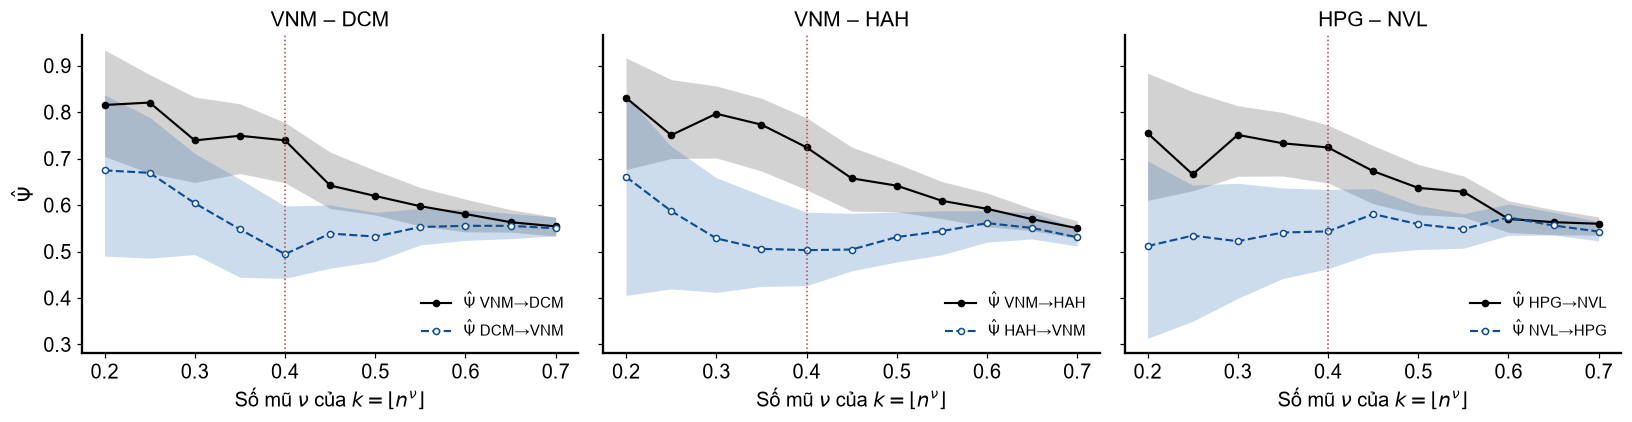

,1,2,3,4,5,6,7,8,9,10,...,51,52,53,54,55,56,57,58,59,60
ν=0.20 (k=4),NVL,VHM,VIC,GEX,EIB,STB,VNM,FRT,VJC,SAB,...,FPT,MBB,TCB,CTG,TCH,CTS,VCI,HDC,HCM,SSI
ν=0.25 (k=6),NVL,FRT,HAG,VJC,TCM,SAB,DGC,VHM,VIC,VNM,...,HDC,TCH,MBB,TCB,CTG,FTS,CTS,VCI,HCM,SSI
ν=0.30 (k=9),NVL,VNM,VJC,SAB,POW,HAG,FRT,TCM,VHC,CTD,...,CTS,DPM,DCM,VPB,MBB,CTG,TCB,HCM,VCI,SSI
ν=0.35 (k=14),NVL,VJC,EIB,VNM,CTD,VHC,DGC,CII,VCB,TCM,...,FTS,VPB,BID,MBB,CTG,TCB,CTS,VCI,HCM,SSI
ν=0.40 (k=21),VNM,VJC,NVL,TCM,HAG,SAB,TCH,PDR,CTD,VHC,...,DPM,FTS,CTS,VCI,BID,MBB,CTG,TCB,SSI,HCM
ν=0.45 (k=31),VJC,EIB,HAG,FRT,VNM,SAB,NVL,TCM,DGC,HDG,...,DPM,TCB,CTS,HSG,NKG,VCI,CTG,MBB,SSI,HCM
ν=0.50 (k=45),VJC,VNM,SAB,NVL,EIB,HAG,FRT,TCM,HDG,MSN,...,DCM,DPM,TCB,MBB,CTG,HSG,NKG,VCI,SSI,HCM
ν=0.55 (k=67),VNM,EIB,SAB,VJC,FRT,TCM,NVL,HAG,MSN,DGC,...,TCB,CTG,BID,DCM,DPM,VCI,HSG,NKG,SSI,HCM
ν=0.60 (k=98),VJC,SAB,VNM,TCM,EIB,FRT,NVL,HAG,MSN,DGC,...,VCI,DCM,DPM,CTG,MBB,TCB,HSG,NKG,HCM,SSI
ν=0.65 (k=144),SAB,VJC,EIB,VNM,TCM,FRT,NVL,HAG,MSN,DGC,...,VCI,CTG,MBB,TCB,DCM,DPM,HSG,NKG,HCM,SSI


In [6]:
nus = np.round(np.arange(0.20, 0.701, 0.05), 2)
order_by_nu = {}
for nu in nus:
    order_by_nu[nu] = CT.ease(CT.tail_coef_matrix(z, k=CT.default_k(n, nu), kind="psi"))
order_nu_tab = pd.DataFrame({f"ν={nu:.2f} (k={CT.default_k(n, nu)})": o for nu, o in order_by_nu.items()},
                            index=range(1, len(SYMBOLS) + 1)).T
U.save_table(order_nu_tab, "02_order_by_k", FOLDER)

top_pairs = diff.reindex(diff.D.abs().sort_values(ascending=False).index).head(3)
top_pairs = [tuple(c.split("–")) if row.D > 0 else tuple(c.split("–")[::-1])
             for c, row in zip(top_pairs.cap, top_pairs.itertuples())]
curves = {pr: {"fwd": [], "bwd": [], "fwd_lo": [], "fwd_hi": [], "bwd_lo": [], "bwd_hi": []} for pr in top_pairs}
for nu in nus:
    kk = CT.default_k(n, nu)
    M = CT.tail_coef_matrix(z, k=kk, kind="psi")
    bt = TP.bootstrap_coef(z, k=kk, kind="psi", B=200, seed=int(nu * 100))
    for a, b in top_pairs:
        f_, b_ = bt[:, iu[a], iu[b]], bt[:, iu[b], iu[a]]
        c = curves[(a, b)]
        c["fwd"].append(M.loc[a, b]); c["bwd"].append(M.loc[b, a])
        c["fwd_lo"].append(np.quantile(f_, 0.05)); c["fwd_hi"].append(np.quantile(f_, 0.95))
        c["bwd_lo"].append(np.quantile(b_, 0.05)); c["bwd_hi"].append(np.quantile(b_, 0.95))

fig, axes = plt.subplots(1, len(top_pairs), figsize=(5 * len(top_pairs), 4), sharey=True)
for ax, (a, b) in zip(np.atleast_1d(axes), top_pairs):
    c = curves[(a, b)]
    ax.fill_between(nus, c["fwd_lo"], c["fwd_hi"], color=PAL["gray_dark"], alpha=0.25, lw=0)
    ax.fill_between(nus, c["bwd_lo"], c["bwd_hi"], color=PAL["blue_secondary"], alpha=0.25, lw=0)
    ax.plot(nus, c["fwd"], "o-", color="black", ms=4, lw=1.4, label=rf"$\hat\Psi$ {a}→{b}")
    ax.plot(nus, c["bwd"], "o--", color=PAL["blue_main"], mfc="white", ms=4, lw=1.4, label=rf"$\hat\Psi$ {b}→{a}")
    ax.axvline(0.4, color=PAL["red_strong"], ls=":", lw=1)
    ax.set_xlabel(r"Số mũ $\nu$ của $k=\lfloor n^{\nu}\rfloor$"); ax.set_title(f"{a} – {b}"); ax.legend(fontsize=10, loc="lower right")
np.atleast_1d(axes)[0].set_ylabel(r"$\hat\Psi$")
U.finalize_figure(fig, "02_k_sensitivity", folder=FOLDER); plt.show()
order_nu_tab

### Phân tích

- **Đầu danh sách thay đổi theo $k$:** NVL là gốc khi $\nu \le 0{,}35$, VNM/VJC khi $\nu$ = 0,40–0,60, SAB khi $\nu \ge 0{,}65$ — cả bốn đều là mã ít nhạy thị trường.
- **Cuối danh sách rất ổn định:** SSI và HCM ở hai vị trí cuối với **mọi** $\nu$; với $k$ lớn, thép (HSG, NKG) thay ngân hàng ở các vị trí áp chót.
- Hệ số của các cặp bất đối xứng lớn nhất hội tụ về mức tương quan chung khi $\nu \to 0{,}7$: với $k$ lớn, "đuôi" lẫn vào thân.

## 6. Biến thể dữ liệu và đuôi: đuôi trên, đuôi dưới, lợi suất thô, lợi suất tuần

**Tính gì:** thứ tự EASE với 3 loại hệ số × 3 biến thể dữ liệu:
- $\hat\Psi$ (hai đuôi); $\hat\Gamma$ (chỉ đuôi trên: cú tăng mạnh); $\hat\Gamma^-$ (chỉ đuôi dưới: cú **sập** — $\hat\Gamma$ áp dụng cho $-X$):
$$\hat\Gamma^-_{jk} = \frac1k\sum_{i\in\mathcal L_j}\big(1-\hat F_k(X_{ik})\big).$$
- Dữ liệu: $z$ (chính), $r$ thô (bị chặn ±7%, có cụm biến động), lợi suất tuần (ít bị chặn hơn, nhưng $n$ chỉ còn ~440, $k=11$).

**So sánh hai thứ tự** bằng độ đồng thuận cặp $\mathrm{agr}(\pi,\pi') = \frac{1}{\binom p2}\sum_{i<j}\mathbb 1\{\text{hai thứ tự xếp } i,j \text{ cùng chiều}\}$
(= 1 − khoảng cách Kendall chuẩn hoá; 1: trùng nhau, 0: đảo ngược hoàn toàn, ~0,5: không liên quan).

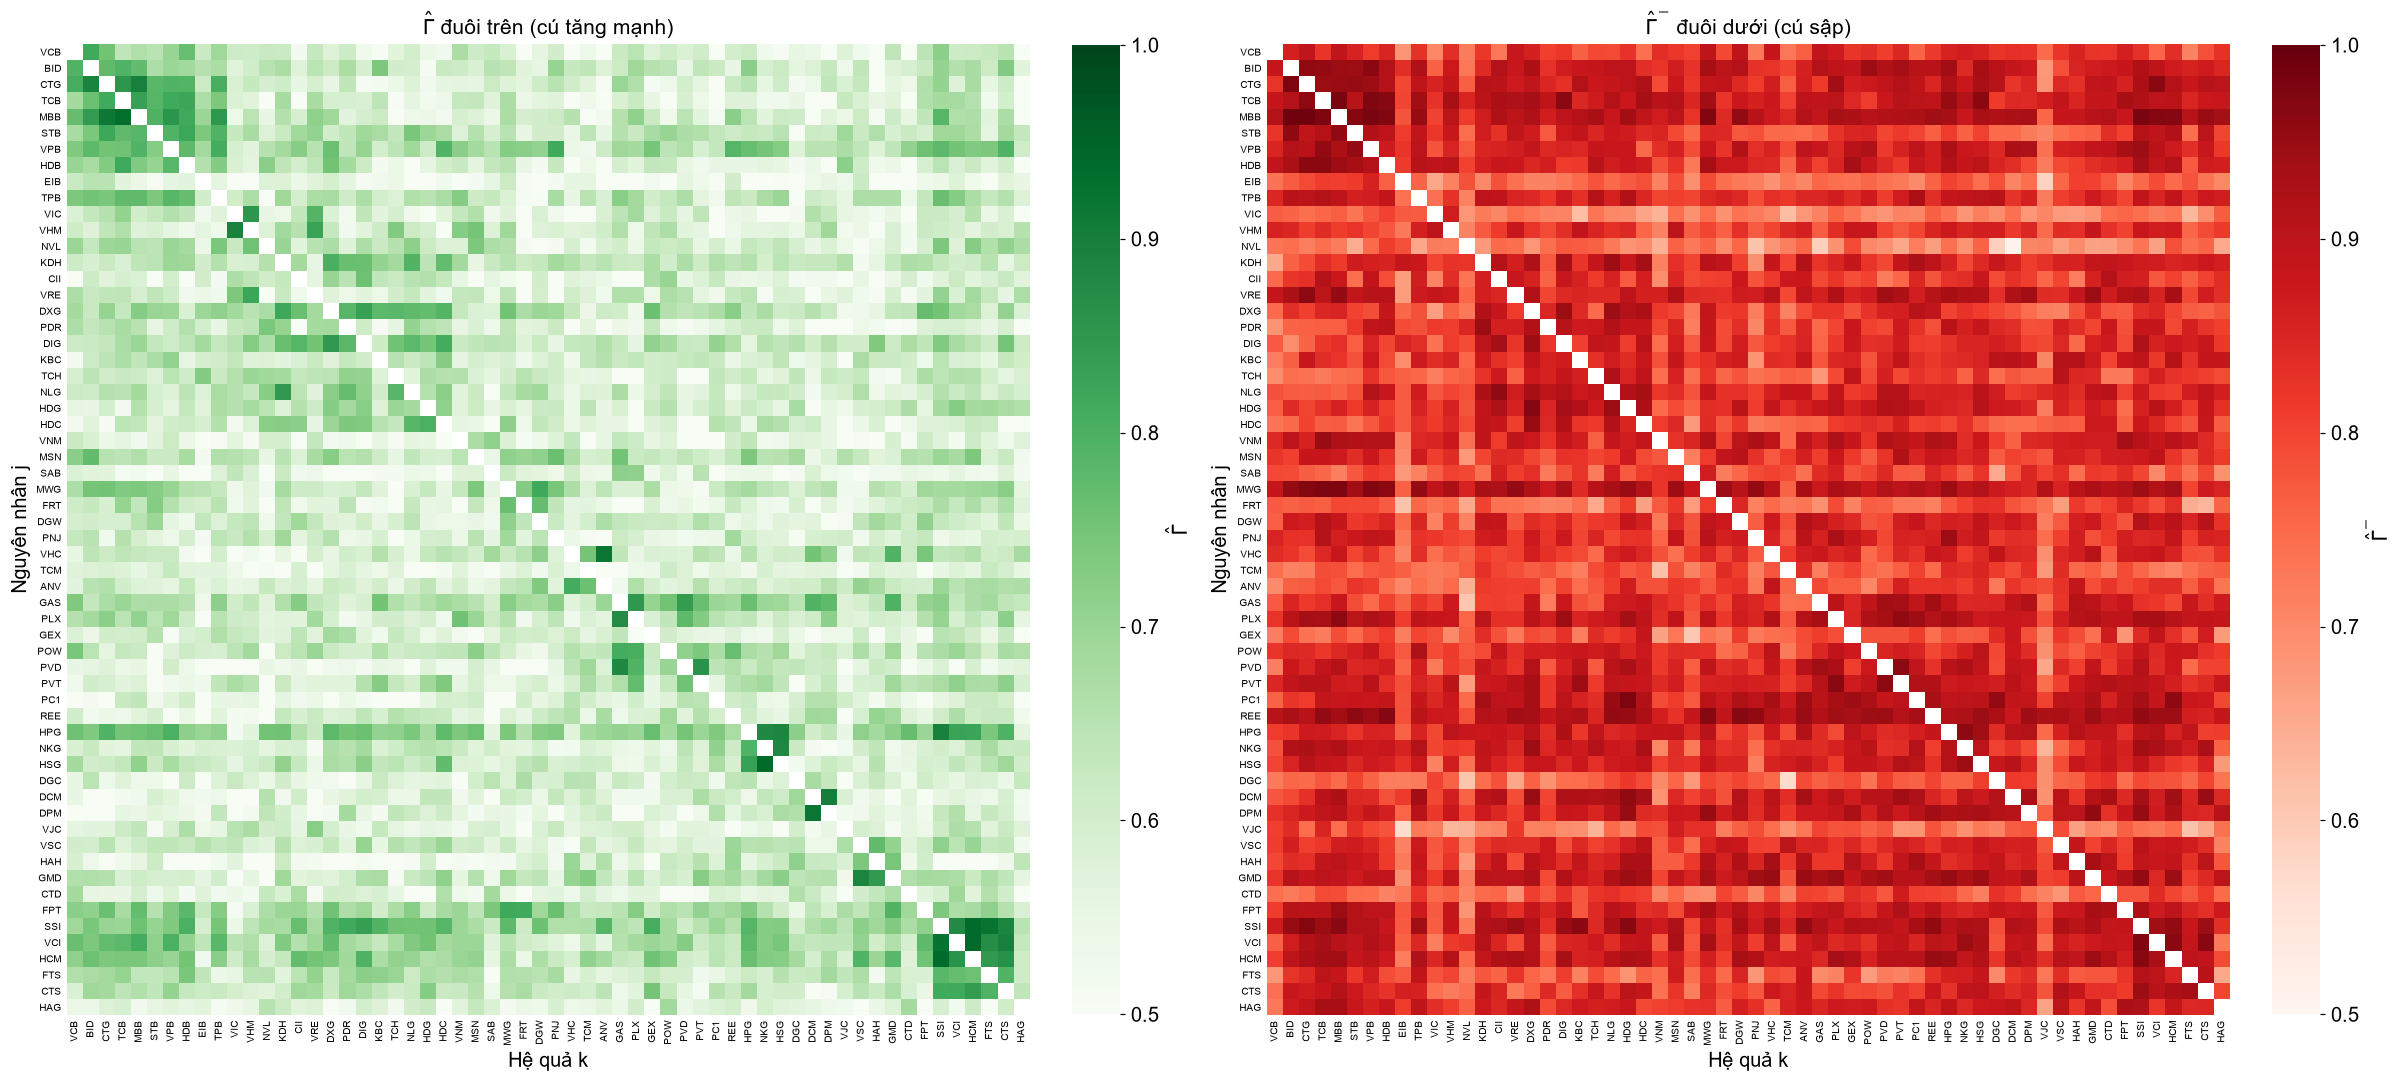

Trung bình ngoài đường chéo: Γ̂ trên = 0.611, Γ̂⁻ dưới = 0.835


,Thứ tự EASE,Đồng thuận với chính
Ngày (r) | Ψ (hai đuôi),VJC → EIB → NVL → TCM → PDR → VNM → MSN → SAB ...,0.796
Ngày (r) | Γ (đuôi trên),SAB → VJC → EIB → VNM → HAG → PDR → NVL → PVD ...,0.790
Ngày (r) | Γ⁻ (đuôi dưới),EIB → SAB → MSN → PDR → NVL → TCM → VNM → VJC ...,0.764
GARCH (z) | Ψ (hai đuôi),VNM → VJC → NVL → TCM → HAG → SAB → TCH → PDR ...,1.000
GARCH (z) | Γ (đuôi trên),HAG → VJC → DGC → PC1 → EIB → SAB → NVL → POW ...,0.824
GARCH (z) | Γ⁻ (đuôi dưới),NVL → SAB → EIB → VIC → TCM → PDR → VNM → VCB ...,0.747
Tuần | Ψ (hai đuôi),SAB → VSC → TCM → VIC → PDR → NVL → MSN → EIB ...,0.703
Tuần | Γ (đuôi trên),SAB → CTD → VSC → VJC → EIB → PDR → NVL → MSN ...,0.692
Tuần | Γ⁻ (đuôi dưới),EIB → SAB → VJC → TCM → NVL → VSC → PDR → HAH ...,0.724


In [7]:
kinds = {"Ψ (hai đuôi)": "psi", "Γ (đuôi trên)": "gamma_upper", "Γ⁻ (đuôi dưới)": "gamma_lower"}
var_orders = {}
for vname, X in variants.items():
    for kname, kind in kinds.items():
        var_orders[(vname, kname)] = CT.ease(CT.tail_coef_matrix(X, k=CT.default_k(len(X)), kind=kind))
var_tab = pd.DataFrame({f"{v} | {k}": " → ".join(o) for (v, k), o in var_orders.items()}, index=["Thứ tự EASE"]).T
var_tab["Đồng thuận với chính"] = [TP.order_agreement(o, order_main) for o in var_orders.values()]
U.save_table(var_tab, "02_order_variants", FOLDER)

Gl = CT.tail_coef_matrix(z, k=K, kind="gamma_lower"); Gu = CT.tail_coef_matrix(z, k=K, kind="gamma_upper")
fig, axes = plt.subplots(1, 2, figsize=(22, 10))
U.make_heatmap(axes[0], Gu, cmap="Greens", vmin=0.5, vmax=1, fmt=None, tick_fontsize=6.5, cbar_label=r"$\hat\Gamma$", title=r"$\hat\Gamma$ đuôi trên (cú tăng mạnh)")
U.make_heatmap(axes[1], Gl, cmap="Reds", vmin=0.5, vmax=1, fmt=None, tick_fontsize=6.5, cbar_label=r"$\hat\Gamma^{-}$", title=r"$\hat\Gamma^{-}$ đuôi dưới (cú sập)")
for ax in axes:
    ax.set_xlabel("Hệ quả k"); ax.set_ylabel("Nguyên nhân j")
U.finalize_figure(fig, "02_upper_vs_lower", folder=FOLDER); plt.show()
off = ~np.eye(len(SYMBOLS), dtype=bool)
print(f"Trung bình ngoài đường chéo: Γ̂ trên = {Gu.values[off].mean():.3f}, Γ̂⁻ dưới = {Gl.values[off].mean():.3f}")
var_tab

### Phân tích

- **Đuôi dưới mạnh hơn hẳn đuôi trên:** $\bar\Gamma^-$ = 0,835 so với $\bar\Gamma$ = 0,611 — cú **sập** lan rộng hơn cú tăng, nhất quán với EDA
  (phụ thuộc đuôi dưới vượt mức Gaussian ở 1.770/1.770 cặp).
- **Thứ tự vững vừa phải qua 9 biến thể:** đồng thuận với cấu hình chính 0,75–0,82 trên dữ liệu ngày, 0,69–0,72 trên lợi suất tuần (với 20 mã: 0,81–0,88).
  Các mã đứng đầu (NVL, SAB, VJC, EIB, VNM, TCM, PDR) lặp lại ở gần như mọi biến thể; thứ tự chi tiết thì không.

## 7. So sánh với các baseline

**Tính gì:** chạy trên cùng dữ liệu $z$:

| Phương pháp | Ý tưởng | Đầu ra |
|---|---|---|
| **Pairwise LiNGAM** (DirectLiNGAM, độ đo `pwling`) | Mô hình tuyến tính, nhiễu không chuẩn; tìm biến ngoại sinh bằng tỷ số hợp lý cặp đôi | thứ tự |
| **ICA-LiNGAM** | Phân tích thành phần độc lập (ICA) của $X = (I-B)^{-1}\varepsilon$, hoán vị $B$ về tam giác dưới | thứ tự (đồng thuận 10 seed, cột xáo trộn) |
| **Rank PC** | Thuật toán PC (kiểm định độc lập có điều kiện), trên điểm chuẩn theo hạng, mức $5\cdot10^{-4}$ | CPDAG (lớp tương đương) |
| **Ngẫu nhiên** | Hoán vị đều | thứ tự (1000 lần) |

Khác biệt cốt lõi: LiNGAM/PC dùng **toàn bộ** phân phối (phần thân chiếm đa số), EASE chỉ dùng $2k = 42$ phiên cực trị của mỗi mã.
Không có "đáp án đúng" cho dữ liệu thật, nên ta đo **mức đồng thuận** giữa các phương pháp và **độ ổn định** của từng phương pháp.

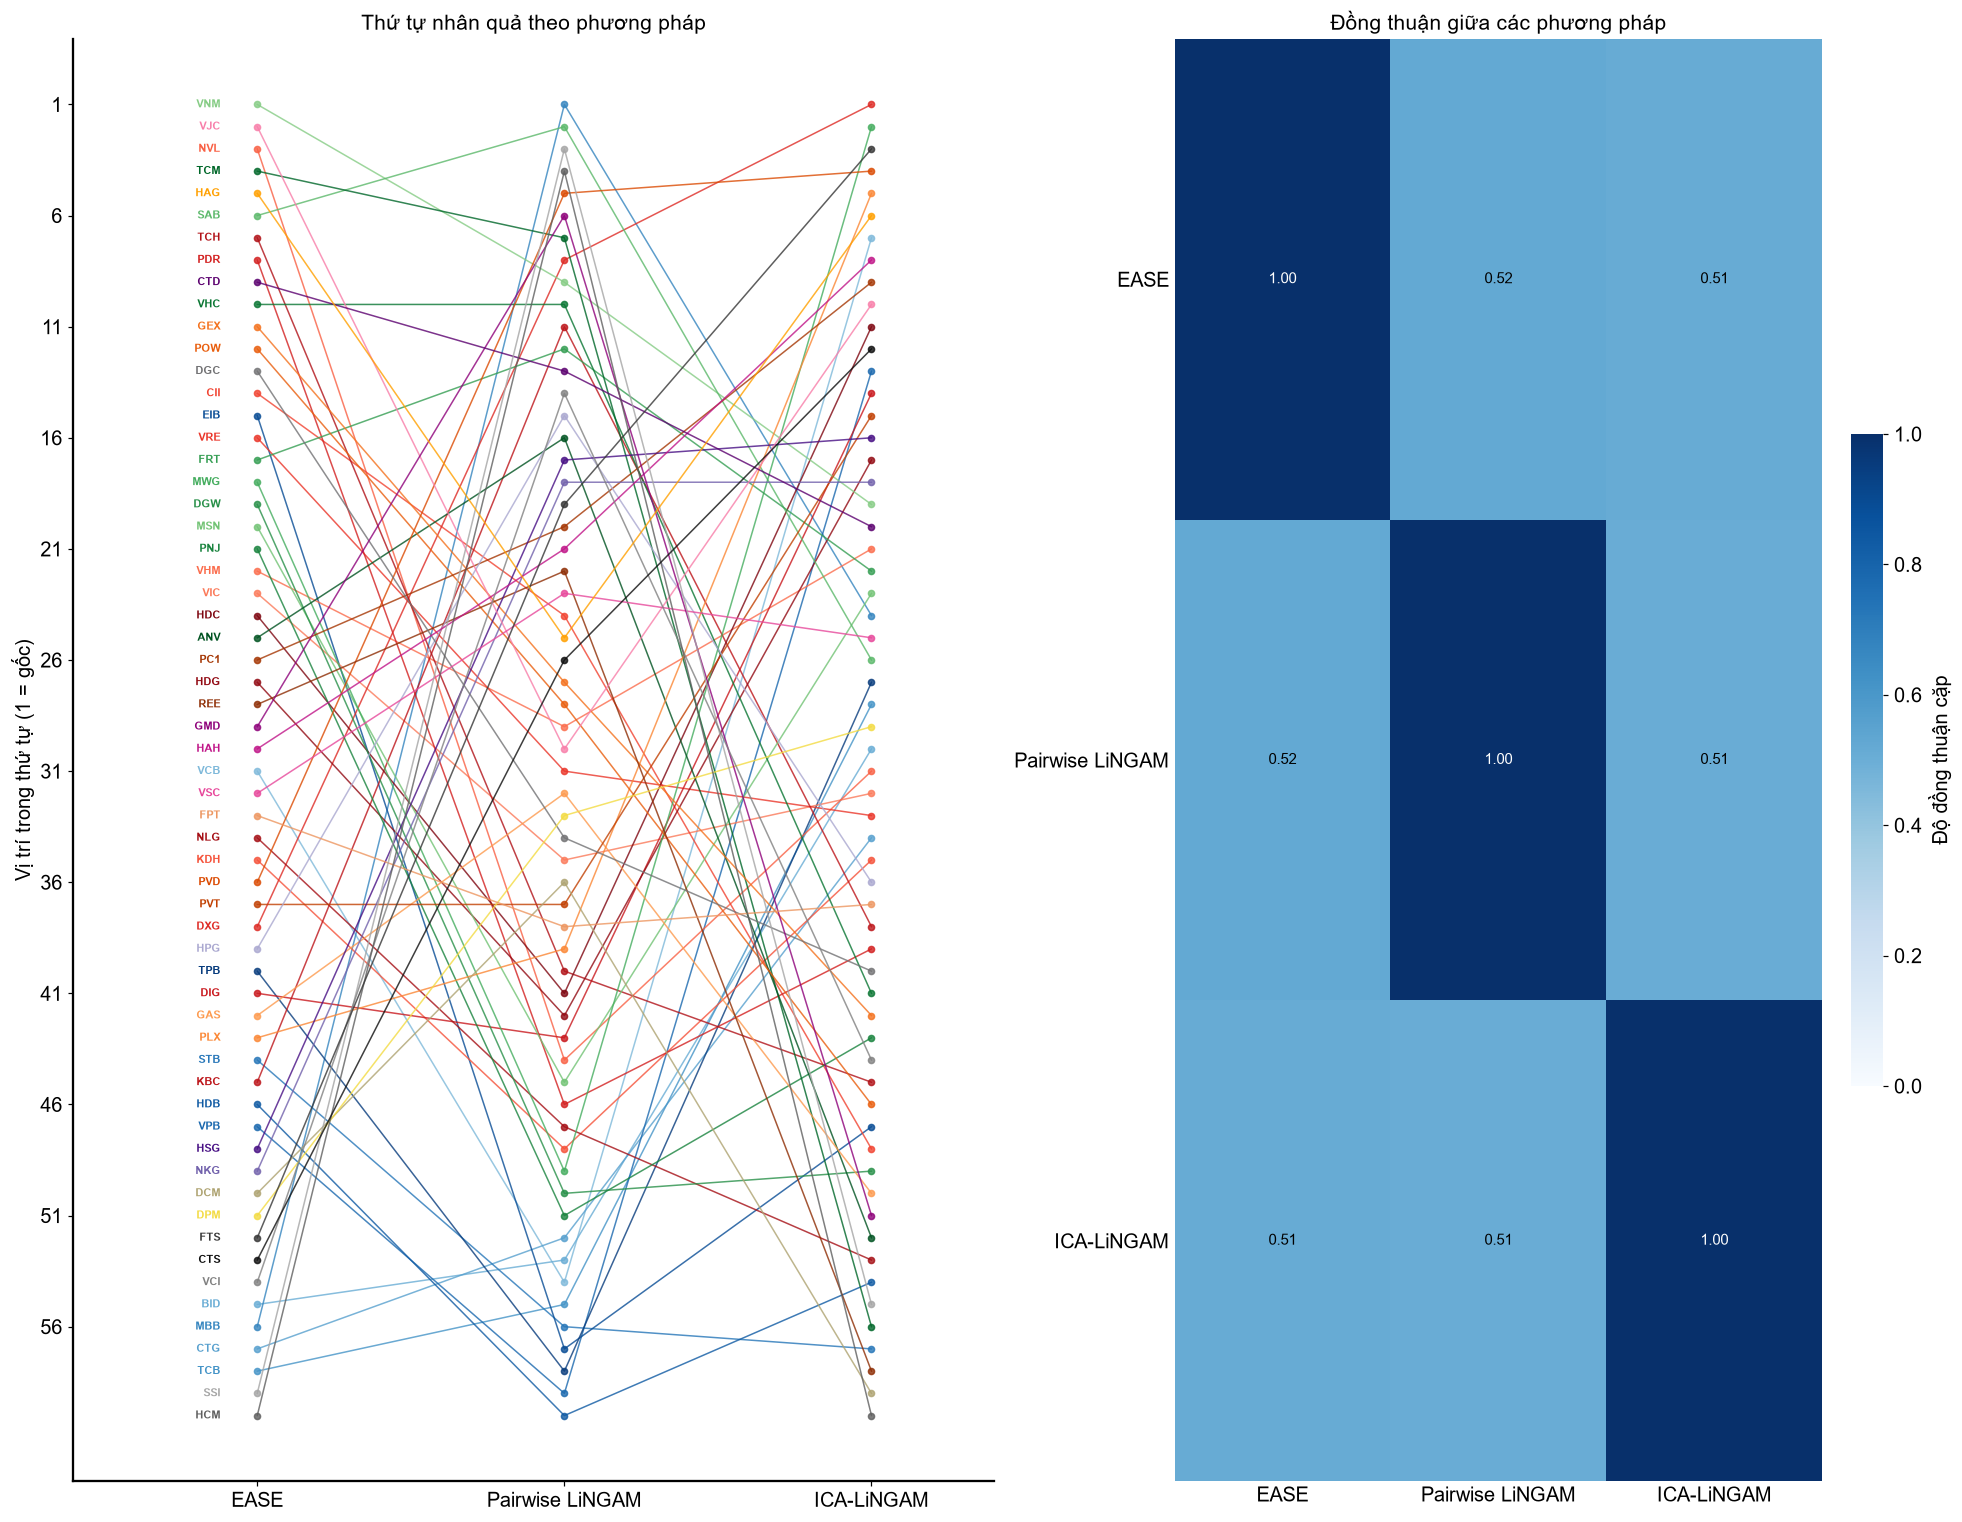

ICA-LiNGAM: đồng thuận cặp trung bình giữa 10 seed = 0.50
Rank PC (CPDAG): VCB → BID, VCB → VNM, VCB → SAB, VCB → VJC, BID → MBB, BID → POW, CTG → VCB, CTG → BID, CTG → MBB, CTG → VPB, CTG → TPB, CTG → SSI, TCB → VRE, TCB → MWG, MBB → TCB, MBB → VPB, MBB → HDB, MBB → TPB, MBB → HPG, MBB → CTD, STB → CTG, STB → TCB, STB → MBB, STB → HDB, STB → TPB, VPB → TCB, VPB → HDB, VPB → TPB, HDB → TCB, HDB → TPB, HDB → VJC, EIB → STB, EIB → GEX, TPB → TCB, VIC → VHM, VHM → MSN, VHM → GEX, KDH → KBC, KDH → HDC, CII → DIG, CII → TCH, CII → HDC, CII → POW, CII → CTD, VRE → VIC, VRE → VHM, VRE → VJC, DXG → NVL, DXG → KDH, DXG — PDR, DXG — DIG, DXG → NLG, DXG → HDG, DXG → HDC, DXG → GEX, PDR → NVL, PDR → KDH, PDR — NLG, PDR → DGW, DIG → PDR, DIG → NLG, DIG → HDC, KBC → HDG, TCH → PDR, TCH → DIG, TCH → KBC, TCH → NLG, NLG → KDH, NLG → HDG, NLG → HDC, HDG → HDC, HDC → GMD, MSN → VNM, MSN → SAB, MSN → MWG, SAB → VNM, MWG → FRT, MWG → PNJ, MWG → REE, MWG → FPT, MWG → SSI, FRT → KDH, FRT — VHC, DGW → HDG, D

,EASE,Pairwise LiNGAM,ICA-LiNGAM
EASE,1.000,0.521,0.509
Pairwise LiNGAM,0.521,1.000,0.506
ICA-LiNGAM,0.509,0.506,1.000


In [8]:
rng = np.random.default_rng(2026)
Z = z.to_numpy()
base_orders = {"EASE": order_main,
               "Pairwise LiNGAM": [SYMBOLS[i] for i in CB.run_pairwise_lingam(Z)["order"]]}
ica_idx, ica_pos = CB.ica_lingam_consensus(Z, seeds=range(10))            # cột xáo trộn theo seed, đồng thuận Borda
base_orders["ICA-LiNGAM"] = [SYMBOLS[i] for i in ica_idx]
ica_orders = [[SYMBOLS[i] for i in np.argsort(row)] for row in ica_pos]
pc_adj = CB.run_rank_pc(Z)["adj"]
pc_edges = [(SYMBOLS[i], SYMBOLS[j], "—" if pc_adj[j, i] else "→") for i in range(len(SYMBOLS)) for j in range(len(SYMBOLS))
            if pc_adj[i, j] and (i < j or not pc_adj[j, i])]
rand_agree = [TP.order_agreement(list(rng.permutation(SYMBOLS)), order_main) for _ in range(1000)]

names = list(base_orders)
agree = pd.DataFrame([[TP.order_agreement(base_orders[a], base_orders[b]) for b in names] for a in names],
                     index=names, columns=names)
U.save_table(agree, "02_baseline_agreement", FOLDER)
U.save_table(pd.DataFrame({m: o for m, o in base_orders.items()}, index=range(1, len(SYMBOLS) + 1)).T, "02_baseline_orders", FOLDER)

fig, axes = plt.subplots(1, 2, figsize=(18, 14), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
for s in SYMBOLS:
    ranks = [base_orders[m].index(s) + 1 for m in names]
    ax.plot(range(len(names)), ranks, "o-", color=COL[s], lw=1, ms=4, alpha=0.8)
    ax.text(-0.12, ranks[0], s, color=COL[s], ha="right", va="center", fontsize=7, fontweight="bold")
ax.set_xticks(range(len(names)), names); ax.set_yticks(range(1, len(SYMBOLS) + 1, 5)); ax.invert_yaxis()
ax.set_ylabel("Vị trí trong thứ tự (1 = gốc)"); ax.set_title("Thứ tự nhân quả theo phương pháp")
ax.set_xlim(-0.6, len(names) - 0.6)
U.make_heatmap(axes[1], agree, cmap="Blues", vmin=0, vmax=1, cbar_label="Độ đồng thuận cặp",
               title="Đồng thuận giữa các phương pháp")
U.finalize_figure(fig, "02_baseline_comparison", folder=FOLDER); plt.show()

print(f"ICA-LiNGAM: đồng thuận cặp trung bình giữa 10 seed = "
      f"{np.mean([TP.order_agreement(a, b) for i, a in enumerate(ica_orders) for b in ica_orders[i + 1:]]):.2f}")
print("Rank PC (CPDAG):", ", ".join(f"{a} {e} {b}" for a, b, e in pc_edges) or "không có cạnh")
print(f"Đồng thuận của thứ tự ngẫu nhiên với EASE: trung bình {np.mean(rand_agree):.2f}, "
      f"phân vị 95% = {np.quantile(rand_agree, 0.95):.2f}")
agree

### Phân tích

- **Ba phương pháp hoàn toàn không đồng thuận** với 60 mã: EASE–Pairwise LiNGAM 0,52, EASE–ICA-LiNGAM 0,51, hai LiNGAM 0,51 — đều trong dải của thứ tự ngẫu nhiên (trung bình 0,50, phân vị 95% = 0,57).
- **ICA-LiNGAM không ổn định:** đồng thuận trung bình giữa 10 seed chỉ 0,50 — tức ngẫu nhiên; với 60 biến và nhiễu gần chuẩn ở phần thân, ICA không tách được nguồn.
- Pairwise LiNGAM đặt **MBB, SSI, HCM ở đầu** và các ngân hàng nhỏ (EIB, TPB, VPB, HDB) ở cuối — gần như **ngược** EASE (chứng khoán và ngân hàng lớn ở cuối). Hai phương pháp đo hai thứ khác nhau:
  LiNGAM dùng phần thân, nơi nhân tố chung (mã tải cao) trông như "nguồn"; EASE dùng đuôi, nơi mã tải cao là mã "bị kéo theo" nhiều nhất.
- Rank PC trả về CPDAG dày đặc, các cạnh chủ yếu trong cùng ngành (ngân hàng, bất động sản, chứng khoán) — dấu hiệu nhân tố ngành không quan sát được.

## 8. Kết luận

1. **Phụ thuộc đuôi mạnh, theo ngành:** $\overline{\hat\Psi}$ = 0,66, cùng ngành 0,69 > khác ngành 0,65; mạnh nhất trong chứng khoán (SSI–HCM 0,94), ngân hàng (MBB–TCB 0,91) và thép.
2. **Thứ tự EASE ổn định ở mức nhóm:** mã ít nhạy thị trường (NVL, VJC, VNM, SAB, HAG) ở đầu — nhưng không mã nào làm gốc quá 30% bootstrap; chứng khoán (SSI, HCM) luôn ở cuối.
3. **Cú sập lan mạnh hơn cú tăng** ($\bar\Gamma^-$ 0,84 so với $\bar\Gamma$ 0,61).
4. **Baseline không đồng thuận** với EASE (0,51–0,52, bằng mức ngẫu nhiên).
5. **Câu hỏi để kiểm chứng:** thứ tự "ít nhạy → nhạy với thị trường" gợi ý EASE đang xếp theo hệ số tải của nhân tố chung — Validation kiểm tra trực tiếp.